# Imports

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

# Konstante in parametri rakete (enako kot na vaji 02)
G, M_Z, R_Z = 6.67430e-11, 5.972e24, 6371e3
rho_0, M_zraka, R_plin, T_0 = 1.225, 28.96, 8314.46, 288.15
C_d, S = 0.2, 10.0
F_pot, v_izp = 845e3, 2500.0
mdot = F_pot / v_izp
m_rak, m_tov = 10_000, 1_000
g0 = G * M_Z / R_Z**2
H = R_plin * T_0 / (M_zraka * g0)

# Funkcije

In [2]:
def gostota(h):
    return rho_0 * np.exp(-np.maximum(h, 0) / H)


def pospesek(h, v, m_g, m_t=m_tov, delez=1.0):
    """Pospešek rakete (potisk + gravitacija + upor) - model z vaje 02.
    delez: del koraka, v katerem motor še deluje (zadnji korak pred izgorevanjem)."""
    m = m_rak + m_t + m_g
    F = (delez * F_pot if m_g > 0 else 0.0) - G * M_Z * m / (R_Z + h)**2 \
        - 0.5 * gostota(h) * C_d * S * v * abs(v)
    return F / m


def simulacija_euler(m_g0, dt, m_t=m_tov):
    """Eksplicitna Eulerjeva metoda do najvišje točke. Vrne DataFrame (t, h, v, m_g)."""
    t, h, v, m_g = 0.0, 0.0, 0.0, float(m_g0)
    zapis = [(t, h, v, m_g)]
    while True:
        delez = min(1.0, m_g / (mdot * dt))   # gorivo lahko pošle sredi koraka
        a = pospesek(h, v, m_g, m_t, delez)
        h, v, m_g, t = h + v * dt, v + a * dt, max(m_g - mdot * dt, 0.0), t + dt
        zapis.append((t, h, v, m_g))
        if v < 0:
            break
    return pd.DataFrame(zapis, columns=["t", "h", "v", "m_g"])


def desna_stran(t, y, m_t=m_tov):
    """Desna stran sistema dy/dt za y = [h, v, m_g] (za solve_ivp)."""
    h, v, m_g = y
    return [v, pospesek(h, v, m_g, m_t), -mdot if m_g > 0 else 0.0]


def dogodek_vrh(t, y, m_t=m_tov):
    return y[1]            # v = 0
dogodek_vrh.terminal = True
dogodek_vrh.direction = -1


def simulacija_ivp(m_g0, m_t=m_tov, rtol=1e-8):
    """Let v dveh delih: do izgorevanja (t_b = m_g0/mdot) in od izgorevanja do vrha.
    Vrne DataFrame (t, h, v, m_g) na gosti mreži časov."""
    t_b = m_g0 / mdot
    r1 = solve_ivp(desna_stran, (0, t_b), [0.0, 0.0, m_g0], args=(m_t,),
                   rtol=rtol, atol=1e-6, dense_output=True)
    y_b = r1.y[:, -1].copy()
    y_b[2] = 0.0
    r2 = solve_ivp(desna_stran, (t_b, t_b + 3600), y_b, args=(m_t,), events=dogodek_vrh,
                   rtol=rtol, atol=1e-6, dense_output=True)
    t1 = np.linspace(0, t_b, 400)
    t2 = np.linspace(t_b, r2.t[-1], 800)[1:]
    Y = np.hstack([r1.sol(t1), r2.sol(t2)])
    return pd.DataFrame({"t": np.r_[t1, t2], "h": Y[0], "v": Y[1], "m_g": Y[2]})


def analiza_leta(df):
    """Vrne slovar: h_max, t_vrh, a_max, q_max (dinamični tlak) in h_q (višina pri q_max)."""
    a = np.gradient(df["v"].to_numpy(), df["t"].to_numpy())
    q = 0.5 * gostota(df["h"].to_numpy()) * df["v"].to_numpy()**2
    k = int(np.argmax(q))
    return {"h_max": df["h"].max(), "t_vrh": df["t"].iloc[-1], "a_max": a.max(),
            "q_max": q[k], "h_q": df["h"].iloc[k]}

# Testno območje

In [3]:
# P1: prosti met navzgor z Eulerjevo metodo (g = 10 m/s^2, v0 = 50 m/s, dt = 1 s)
h, v, dt = 0.0, 50.0, 1.0
for n in range(3):
    h, v = h + v * dt, v - 10 * dt
print("Euler:   h(3 s) =", h, " v(3 s) =", v)
print("točno:   h(3 s) =", 50 * 3 - 5 * 3**2, " v(3 s) =", 50 - 10 * 3)

# P3: dinamični tlak pri konstantnem pospešku ima vrh pri h = H
a0 = (F_pot - (m_rak + m_tov + 20_000) * g0) / (m_rak + m_tov + 20_000)
print(f"a0 = {a0:.2f} m/s^2, H = {H:.0f} m, q_max(ocena) = {rho_0 * a0 * H / np.e / 1e3:.1f} kPa")

Euler:   h(3 s) = 120.0  v(3 s) = 20.0
točno:   h(3 s) = 105  v(3 s) = 20
a0 = 17.44 m/s^2, H = 8424 m, q_max(ocena) = 66.2 kPa


# Naloga 1

In [4]:
m_g0 = 20_000
koraki = [10, 5, 2, 1, 0.1, 0.01]
t0 = time.time()
ref = analiza_leta(simulacija_euler(m_g0, 0.001))  # referenčna rešitev
print(f"referenca (dt = 0.001 s): h_max = {ref['h_max']/1e3:.3f} km, {time.time()-t0:.1f} s")
rez = []
for dt in koraki:
    t0 = time.time()
    a = analiza_leta(simulacija_euler(m_g0, dt))
    rez.append({"dt": dt, "h_max [km]": a["h_max"] / 1e3, "t_vrh [s]": a["t_vrh"],
                "napaka [m]": abs(a["h_max"] - ref["h_max"]), "cas [s]": time.time() - t0})
rez = pd.DataFrame(rez)
rez

referenca (dt = 0.001 s): h_max = 193.928 km, 1.4 s


,dt,h_max [km],t_vrh [s],napaka [m],cas [s]
0,10.00,127.000528,200.00,66927.770647,0.001099
1,5.00,158.187500,220.00,35740.797872,0.001124
2,2.00,179.023595,234.00,14904.703157,0.001097
3,1.00,186.322806,237.00,7605.492604,0.001591
4,0.10,193.163572,240.70,764.726211,0.010223
5,0.01,193.858664,241.03,69.633778,0.101830


# Naloga 1 - Slika 1

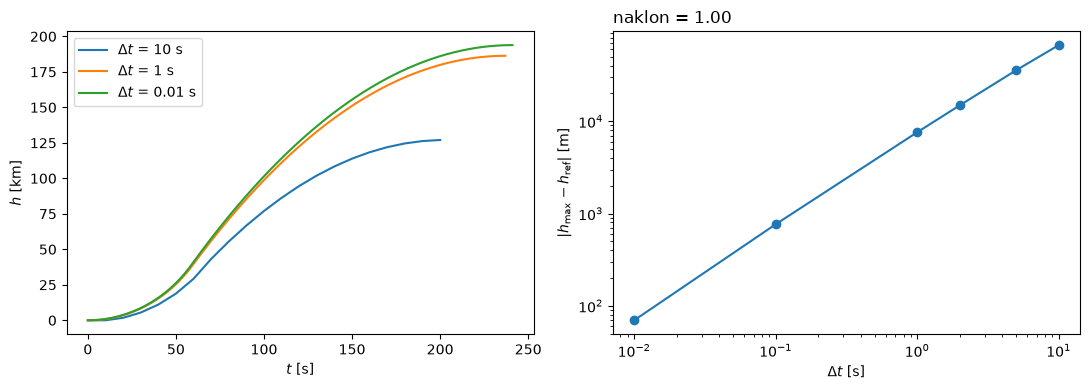

In [5]:
fig = plt.figure(figsize=(11, 4))
ax = fig.add_subplot(121)
for dt in (10, 1, 0.01):
    d = simulacija_euler(m_g0, dt)
    ax.plot(d["t"], d["h"] / 1e3, label=f"$\\Delta t$ = {dt} s")
ax.set_xlabel("$t$ [s]")
ax.set_ylabel("$h$ [km]")
ax.legend()
ax = fig.add_subplot(122)
ax.loglog(rez["dt"], rez["napaka [m]"], "o-")
k, n = np.polyfit(np.log10(rez["dt"]), np.log10(rez["napaka [m]"]), 1)
ax.set_title(f"naklon = {k:.2f}", loc="left")
ax.set_xlabel(r"$\Delta t$ [s]")
ax.set_ylabel(r"$|h_{\max} - h_{\rm ref}|$ [m]")
fig.tight_layout()
plt.show()

# Naloga 2

In [6]:
t0 = time.time()
d_ivp = simulacija_ivp(m_g0)
t_ivp = time.time() - t0
a_ivp = analiza_leta(d_ivp)
print(f"solve_ivp: h_max = {a_ivp['h_max']/1e3:.3f} km, t_vrh = {a_ivp['t_vrh']:.2f} s, čas {t_ivp:.3f} s")
print(f"           q_max = {a_ivp['q_max']/1e3:.1f} kPa pri h = {a_ivp['h_q']/1e3:.2f} km, a_max = {a_ivp['a_max']:.1f} m/s^2")
print(f"Euler 0.001 s: h_max = {ref['h_max']/1e3:.3f} km, t_vrh = {ref['t_vrh']:.2f} s")

solve_ivp: h_max = 193.936 km, t_vrh = 241.07 s, čas 0.015 s
           q_max = 79.0 kPa pri h = 9.62 km, a_max = 63.7 m/s^2
Euler 0.001 s: h_max = 193.928 km, t_vrh = 241.06 s


# Naloga 3

In [7]:
mase = [1_000, 2_000, 4_000, 8_000, 16_000, 32_000, 64_000]
studija = pd.DataFrame([{"m_g [t]": m / 1e3, **analiza_leta(simulacija_ivp(m))} for m in mase])
studija["h_max"] /= 1e3
studija["h_q"] /= 1e3
studija["q_max"] /= 1e3
studija.round(2)

,m_g [t],h_max,t_vrh,a_max,q_max,h_q
0,1.0,1.76,19.97,63.34,20.28,0.27
1,2.0,5.04,33.23,57.79,61.89,1.00
2,4.0,12.71,52.96,48.92,127.92,3.35
3,8.0,35.75,94.20,41.91,137.88,9.35
4,16.0,132.01,194.86,58.97,93.66,9.53
5,32.0,366.84,351.05,66.57,50.18,9.97
6,64.0,613.49,527.38,66.30,19.64,12.07


# Naloga 3 - Slika 2

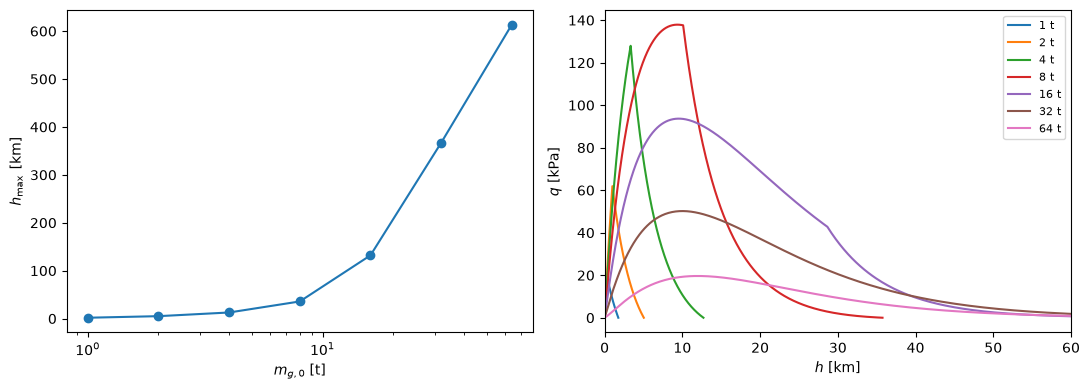

In [8]:
fig = plt.figure(figsize=(11, 4))
ax = fig.add_subplot(121)
ax.semilogx(studija["m_g [t]"], studija["h_max"], "o-")
ax.set_xlabel("$m_{g,0}$ [t]")
ax.set_ylabel(r"$h_{\max}$ [km]")
ax = fig.add_subplot(122)
for m in mase:
    d = simulacija_ivp(m)
    q = 0.5 * gostota(d["h"]) * d["v"]**2
    ax.plot(d["h"] / 1e3, q / 1e3, label=f"{m/1e3:g} t")
ax.set_xlim(0, 60)
ax.set_xlabel("$h$ [km]")
ax.set_ylabel("$q$ [kPa]")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

# Naloga 4

In [9]:
for m_t in (0, 1_000, 5_000, 10_000):
    f = lambda m: simulacija_ivp(m, m_t)["h"].max() - 100e3
    m_min = brentq(f, 500, 60_000, xtol=1.0)
    print(f"m_tovor = {m_t/1e3:4.0f} t  ->  m_g,min = {m_min/1e3:.2f} t, t_b = {m_min/mdot:.1f} s")

m_tovor =    0 t  ->  m_g,min = 12.92 t, t_b = 38.2 s
m_tovor =    1 t  ->  m_g,min = 13.80 t, t_b = 40.8 s
m_tovor =    5 t  ->  m_g,min = 17.81 t, t_b = 52.7 s
m_tovor =   10 t  ->  m_g,min = 24.35 t, t_b = 72.0 s
